In [1]:
import os

os.environ["NUMBA_NUM_THREADS"] = "1"
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import faulthandler
from pathlib import Path

crash_path = Path.home() / "Desktop" / "EMM-Project" / "regression_crash.log"
crash_log = crash_path.open("a", buffering=1)
faulthandler.enable(file=crash_log, all_threads=True)

print("Thread settings applied; crash logging enabled.")

Thread settings applied; crash logging enabled.


In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import pyfixest as pf
import matplotlib.pyplot as plt

from scipy.special import expit

DATA = Path(
    r"C:\Users\tahai\Desktop\EMM-Project"
    r"\eda_outputs\reciprocity_return.csv"
)

OUT = DATA.parent.parent / "logistic_resgression" / "results"
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
import numpy as np

print("Testing matrix multiplication...", flush=True)

x = np.random.default_rng(0).normal(size=(25_000, 3))
result = x.T @ x

print("Matrix multiplication worked:", result, flush=True)

Testing matrix multiplication...
Matrix multiplication worked: [[ 2.49742929e+04 -3.55285902e+00  1.48768512e+02]
 [-3.55285902e+00  2.48022952e+04 -2.34906421e+02]
 [ 1.48768512e+02 -2.34906421e+02  2.52835145e+04]]


In [4]:
dtypes = {
    "user": "category",
    "subreddit": "category",
    "month": "int8",
    "replies_sent": "int32",
    "replies_received": "int32",
    "reciprocal_partners": "int32",
    "returned_next_month": "int8",
}

df = pd.read_csv(
    DATA,
    usecols=list(dtypes),
    dtype=dtypes,
    keep_default_na=False,
)

df["recip_binary"] = (
    df["reciprocal_partners"] > 0
).astype("int8")

df["log_sent"] = np.log1p(df["replies_sent"])
df["log_received"] = np.log1p(df["replies_received"])

assert len(df) == 36_031_393
assert df["subreddit"].nunique() == 2046
assert not df.isna().any().any()

print("Rows:", len(df))
print("Users:", df["user"].nunique())
print("Subreddits:", df["subreddit"].nunique())

Rows: 36031393
Users: 3354982
Subreddits: 2046


In [5]:
def fit_subreddit(name, group):
    g = group.reset_index(drop=True).copy()
    g["user"] = g["user"].cat.remove_unused_categories()

    result = {
        "subreddit": str(name),
        "rows": len(g),
        "users": g["user"].nunique(),
        "months": g["month"].nunique(),
        "returned": int(g["returned_next_month"].sum()),
        "reciprocated": int(g["recip_binary"].sum()),
    }

    try:
        assert g["returned_next_month"].nunique() == 2, (
            "Only one return outcome."
        )
        assert g["recip_binary"].nunique() == 2, (
            "Only one reciprocity value."
        )
        assert result["users"] > 1, "Too few user clusters."

        month_variation = (
            g.groupby("month")["returned_next_month"].nunique()
        )

        assert month_variation.eq(2).all(), (
            "A month has only one outcome: separated month effect."
        )

        reciprocity = g["recip_binary"].to_numpy(copy=True)

        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter("always")

            model = pf.feglm(
                "returned_next_month ~ "
                "recip_binary + log_sent + log_received | month",
                data=g,
                family="logit",
                vcov={"CRV1": "user"},
                copy_data=False,
                fixef_rm="none",
                iwls_maxiter=100,
            )

        result["warnings"] = " | ".join(
            dict.fromkeys(str(w.message) for w in captured)
        )

        assert model.convergence, "Model did not converge."

        assert set(model.coef().index) == {
            "recip_binary", "log_sent", "log_received"
        }, "A model term was dropped as collinear."

        assert np.isfinite(model.coef()).all()
        assert np.isfinite(model.se()).all()
        assert (model.se() > 0).all()

        eta = np.asarray(model.predict(type="link")).ravel()
        result["fitted_rows"] = len(eta)

        assert len(eta) == result["rows"], (
            "The model excluded observations."
        )
        assert np.isfinite(eta).all()

        estimates = model.tidy().loc["recip_binary"]
        beta = float(estimates["Estimate"])

        eta_without = eta - beta * reciprocity

        ame_pp = 100 * np.mean(
            expit(eta_without + beta) - expit(eta_without)
        )

        result.update(
            status="ok",
            coefficient=beta,
            std_error=float(estimates["Std. Error"]),
            p_value=float(estimates["Pr(>|t|)"]),
            ci_low=float(estimates["2.5%"]),
            ci_high=float(estimates["97.5%"]),
            ame_pp=float(ame_pp),
        )

    except Exception as error:
        result.update(
            status="not_fitted",
            reason=f"{type(error).__name__}: {error}",
        )

    return result

In [6]:
print("1. Selecting one subreddit...", flush=True)

small = df.loc[
    df["subreddit"].eq("2007scape")
].copy()

print(f"2. Selected {len(small):,} rows. Starting fit...", flush=True)

test_result = fit_subreddit("2007scape", small)

print("3. Fit function finished.", flush=True)
print(test_result)

1. Selecting one subreddit...
2. Selected 24,694 rows. Starting fit...
3. Fit function finished.
{'subreddit': '2007scape', 'rows': 24694, 'users': 11413, 'months': 10, 'returned': 12061, 'reciprocated': 15481, 'warnings': '', 'fitted_rows': 24694, 'status': 'ok', 'coefficient': -0.2912675615010466, 'std_error': 0.03697023591348063, 'p_value': 3.3306690738754696e-15, 'ci_low': -0.3637278923914179, 'ci_high': -0.2188072306106753, 'ame_pp': -5.732618814729713}


In [7]:
records = []
total = df["subreddit"].nunique()

groups = df.groupby(
    "subreddit",
    observed=True,
    sort=True,
)

for number, (name, group) in enumerate(groups, start=1):
    records.append(fit_subreddit(name, group))

    if number == 1 or number % 25 == 0 or number == total:
        successful = sum(r["status"] == "ok" for r in records)

        print(
            f"{number}/{total} processed; "
            f"{successful} successful fits.",
            flush=True,
        )

        pd.DataFrame(records).to_csv(
            OUT / "subreddit_logistic_checkpoint.csv",
            index=False,
        )

results = pd.DataFrame(records)

results.to_csv(
    OUT / "subreddit_logistic_results.csv",
    index=False,
)

display(results["status"].value_counts())

1/2046 processed; 1 successful fits.
25/2046 processed; 25 successful fits.
50/2046 processed; 50 successful fits.
75/2046 processed; 75 successful fits.
100/2046 processed; 100 successful fits.
125/2046 processed; 125 successful fits.
150/2046 processed; 150 successful fits.
175/2046 processed; 175 successful fits.
200/2046 processed; 200 successful fits.
225/2046 processed; 225 successful fits.
250/2046 processed; 250 successful fits.
275/2046 processed; 275 successful fits.
300/2046 processed; 300 successful fits.
325/2046 processed; 325 successful fits.
350/2046 processed; 350 successful fits.
375/2046 processed; 375 successful fits.
400/2046 processed; 400 successful fits.
425/2046 processed; 425 successful fits.
450/2046 processed; 450 successful fits.
475/2046 processed; 475 successful fits.
500/2046 processed; 500 successful fits.
525/2046 processed; 525 successful fits.
550/2046 processed; 550 successful fits.
575/2046 processed; 575 successful fits.
600/2046 processed; 600 su

status
ok    2046
Name: count, dtype: int64

In [8]:
successful = results.loc[results["status"] == "ok"].copy()
unsuccessful = results.loc[results["status"] != "ok"].copy()

columns = [
    "subreddit",
    "rows",
    "users",
    "coefficient",
    "ci_low",
    "ci_high",
    "ame_pp",
]

if successful.empty:
    display(unsuccessful[["subreddit", "reason"]].head(20))
else:
    # Start with the largest communities.
    display(
        successful.nlargest(20, "rows")[columns].round(4)
    )

    print("Unsuccessful fits:", len(unsuccessful))

    if not unsuccessful.empty:
        display(
            unsuccessful[["subreddit", "rows", "reason"]].head(20)
        )

,subreddit,rows,users,coefficient,ci_low,ci_high,ame_pp
29,funny,1382467,593467,-0.2724,-0.2823,-0.2625,-5.3901
265,pics,1152645,524631,-0.2600,-0.2710,-0.2489,-5.1605
52,AdviceAnimals,996617,416266,-0.2050,-0.2165,-0.1935,-4.1477
57,videos,845372,374183,-0.2789,-0.2917,-0.2660,-5.5152
83,todayilearned,801297,363589,-0.2286,-0.2418,-0.2155,-4.5327
451,WTF,768546,335360,-0.2429,-0.2563,-0.2295,-4.8342
144,gaming,688165,313733,-0.2153,-0.2293,-0.2012,-4.2286
27,worldnews,612859,279388,-0.1488,-0.1639,-0.1337,-2.9450
30,leagueoflegends,586630,208268,-0.3008,-0.3154,-0.2863,-5.7836
436,IAmA,455735,285956,-0.1052,-0.1267,-0.0837,-1.6125


Unsuccessful fits: 0


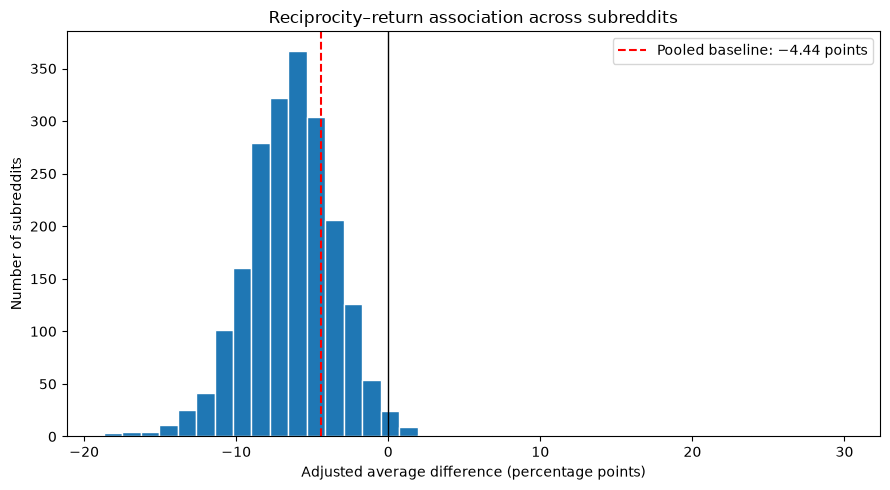

In [9]:
if not successful.empty:
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        successful["ame_pp"],
        bins=40,
        edgecolor="white",
    )

    ax.axvline(
        -4.44,
        color="red",
        linestyle="--",
        label="Pooled baseline: −4.44 points",
    )

    ax.axvline(0, color="black", linewidth=1)

    ax.set_xlabel("Adjusted average difference (percentage points)")
    ax.set_ylabel("Number of subreddits")
    ax.set_title("Reciprocity–return association across subreddits")
    ax.legend()

    fig.tight_layout()
    fig.savefig(
        OUT / "subreddit_adjusted_differences.png",
        dpi=200,
    )

    plt.show()